# 🏥 Medical Insurance Cost Prediction

**Goal:** predict the yearly medical insurance **charges** (in dollars) for a person, using simple personal details.

This is a **regression** problem, because the answer we predict is a number (not a category like yes/no).

### The data (`medical_insurance.csv`)
| Column | Meaning | Type |
|---|---|---|
| `age` | Age of the person (18 to 64) | number |
| `sex` | male / female | text |
| `bmi` | Body Mass Index (weight relative to height) | number |
| `children` | Number of children covered (0 to 5) | number |
| `smoker` | Does the person smoke? yes / no | text |
| `region` | Home region in the US (northeast, northwest, southeast, southwest) | text |
| `charges` | Yearly insurance cost in dollars, **this is what we predict** | number |

### What this notebook does
| Step | What happens | Why |
|---|---|---|
| 1 | Load the data and check its quality | Bad data gives bad predictions |
| 2 | Remove duplicate rows | Copies of the same row would mislead the model |
| 3 | Explore (EDA): distributions, outliers, smoker and BMI effects | Understand what drives cost |
| 4 | Create a BMI category and log-transform the target | Help the models learn better |
| 5 | Encode text columns as numbers | Models only understand numbers |
| 6 | Split into training and test data | Test the model honestly on unseen people |
| 7 | Train and compare 3 models | Find the one with the smallest errors |
| 8 | Save the best model | The Streamlit web app (`app.py`) loads it |

**Headline result:** the best model (Gradient Boosting) explains about **87% of the variation** in charges, with an average error of about **$2,000**. The biggest driver of cost by far is **smoking**.

**How to read this notebook:** above every code cell there is a short explanation of *what* the code does and *why*. The code and outputs are unchanged.

## Step 1: Setup

### 1.1 Import the libraries and set options
A *library* is a ready-made toolbox of code, so we do not have to write everything from scratch.

| Library | What we use it for |
|---|---|
| `numpy` (`np`) | Fast maths on numbers (here: the log transform) |
| `pandas` (`pd`) | Working with tables of data (a *DataFrame* is a table, like Excel inside Python) |
| `matplotlib`, `seaborn` | Drawing charts |
| `train_test_split` | Splitting the data into training and test parts |
| `LabelEncoder`, `StandardScaler` | Encoding and scaling tools (imported here, not needed later) |
| `LinearRegression`, `RandomForestRegressor`, `GradientBoostingRegressor` | The three models we compare |
| `r2_score`, `mean_absolute_error`, `mean_squared_error` | The scores used to judge the models |
| `joblib` | Saving the trained model to a file |

The last lines are display settings: show **all columns** of a table, use a wider screen, give charts a light grid, and set the default chart size.

> 💡 **Tip:** `RANDOM_STATE = "42"` is written as *text* (in quotes), and it is not used later, so the random steps change on every run. It should be the number `42` and be passed to `train_test_split(..., random_state=RANDOM_STATE)` and to the models, so that the results are the same each time.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import joblib
import warnings
warnings.filterwarnings("ignore")


RANDOM_STATE = "42"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## Step 2: Load and inspect the data

### 2.1 Read the CSV file
`pd.read_csv(...)` reads the file into a table called `df`. `df.head(3)` shows the first 3 rows so we can see what the data looks like.

If you get `FileNotFoundError`, the CSV is not in the same folder as the notebook, or `CSV_PATH` has the wrong name.

In [28]:
CSV_PATH = "medical_insurance.csv"   # change this if your file has a different name or location
df = pd.read_csv(CSV_PATH)
df.head(3)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.9240
1,18,male,33.77,1,no,southeast,1725.5523
2,28,male,33.00,3,no,southeast,4449.4620


### 2.2 Size and data types
- `df.shape` gives (rows, columns). Here the file has **2,772 rows and 7 columns**.
- `df.info()` lists every column, how many values are filled in (*non-null*), and its data type.

**What we see:** every column has 2,772 non-null values, so nothing is missing. `age`, `children` are whole numbers, `bmi` and `charges` are decimals, and `sex`, `smoker`, `region` are text.

In [29]:
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (2772, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   str    
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   str    
 5   region    2772 non-null   str    
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 195.5 KB


### 2.3 Summary statistics
`df.describe()` gives, for each numeric column: the count, mean (average), std (how spread out the values are), minimum, quartiles (25%, 50%, 75%) and maximum.

**What we see:** ages run from 18 to 64 (mean about 39), BMI averages about 30.7, and `charges` average about **$13,261** with a very large spread (std about $12,152). A spread this big means costs differ a lot from person to person.

In [30]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


## Step 3: Data quality

### 3.1 Missing values and duplicates
- **Missing values** (blanks) can break models, so we count them.
- **Duplicate rows** are exact copies of another row. They make the model see the same person many times and can leak test data into training.

**What we see:** 0 missing values, but **1,435 duplicate rows**, more than half of the file.

In [31]:
print("Missing values in the whole table:",df.isna().sum().sum()) 
print("Duplicate Values in the whole table:", df.duplicated().sum())

Missing values in the whole table: 0
Duplicate Values in the whole table: 1435


### 3.2 How are the duplicates spread?
We group the rows by *all* columns and count how many times each distinct row appears (`.size()`). Then `value_counts()` tells us how many distinct rows appear 2 times, 4 times, and so on.

**What we see:** 1,288 distinct rows appear **twice** and 49 appear **four times**. This means the data was most likely appended to itself. That is why the file has 2,772 rows but only 1,337 distinct people.

In [32]:
dup_counts = df.groupby(list(df.columns)).size().reset_index(name="count")
dup_counts = dup_counts["count"].value_counts().sort_index()
dup_counts


count
2    1288
4      49
Name: count, dtype: int64

### 3.3 Remove the duplicates
`drop_duplicates()` keeps only one copy of each row, and `reset_index(drop=True)` renumbers the rows from 0 so there are no gaps.

**Result:** **1,337 unique rows** remain. This is the clean dataset used for the rest of the project.

In [33]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(1337, 7)

## Step 4: Exploratory Data Analysis (EDA)
EDA means *looking at the data with tables and charts* to understand it before modelling.

### 4.1 The text columns
For `sex`, `smoker` and `region` we show how many people fall in each group (`value_counts()`) and the same as proportions (`normalize=True`).

**What we see:** men and women are almost equally common (50.5% vs 49.5%). About **20.5% of people are smokers** (274 of 1,337). Smokers are a minority, which is important because they turn out to pay much more.

In [34]:
for col in ["sex", "smoker", "region"]:
    print(f"--------------------{col}-----------------")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True).round(3))

--------------------sex-----------------
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.505
female    0.495
Name: proportion, dtype: float64
--------------------smoker-----------------
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
--------------------region-----------------
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272
southwest    0.243
northwest    0.242
northeast    0.242
Name: proportion, dtype: float64


### 4.2 Skewness and kurtosis
- **Skewness** says how lopsided a distribution is. Near 0 = symmetric, above about 1 = a long tail to the right (a few very large values).
- **Kurtosis** says how heavy the tails are compared with a normal bell curve.

**What we see:** `age` (0.05) and `bmi` (0.28) are fairly symmetric. `charges` has a skew of **1.52**: most people pay a modest amount, while a few pay a lot. This is the reason for the log transform in Step 6.

In [35]:
df.columns
for col in ["age","bmi", "children", "charges"]:
    print(f"{col}: skew = {df[col].skew():.3f}, kurtosis = {df[col].kurt():.3f}")

age: skew = 0.055, kurtosis = -1.244
bmi: skew = 0.284, kurtosis = -0.053
children: skew = 0.937, kurtosis = 0.201
charges: skew = 1.515, kurtosis = 1.604


### 4.3 Histograms
A histogram shows how many people fall into each value range. The smooth line (`kde=True`) outlines the same shape. The 2×2 grid shows `age`, `bmi`, `children` and `charges` side by side.

**What to notice:**
- `age` is spread fairly evenly across 18 to 64.
- `bmi` looks like a bell curve centred around 30.
- `children` is concentrated at 0 to 2.
- `charges` has a tall peak on the left and a long tail to the right (the skew we measured).

Text(0.5, 1.0, 'charges Description')

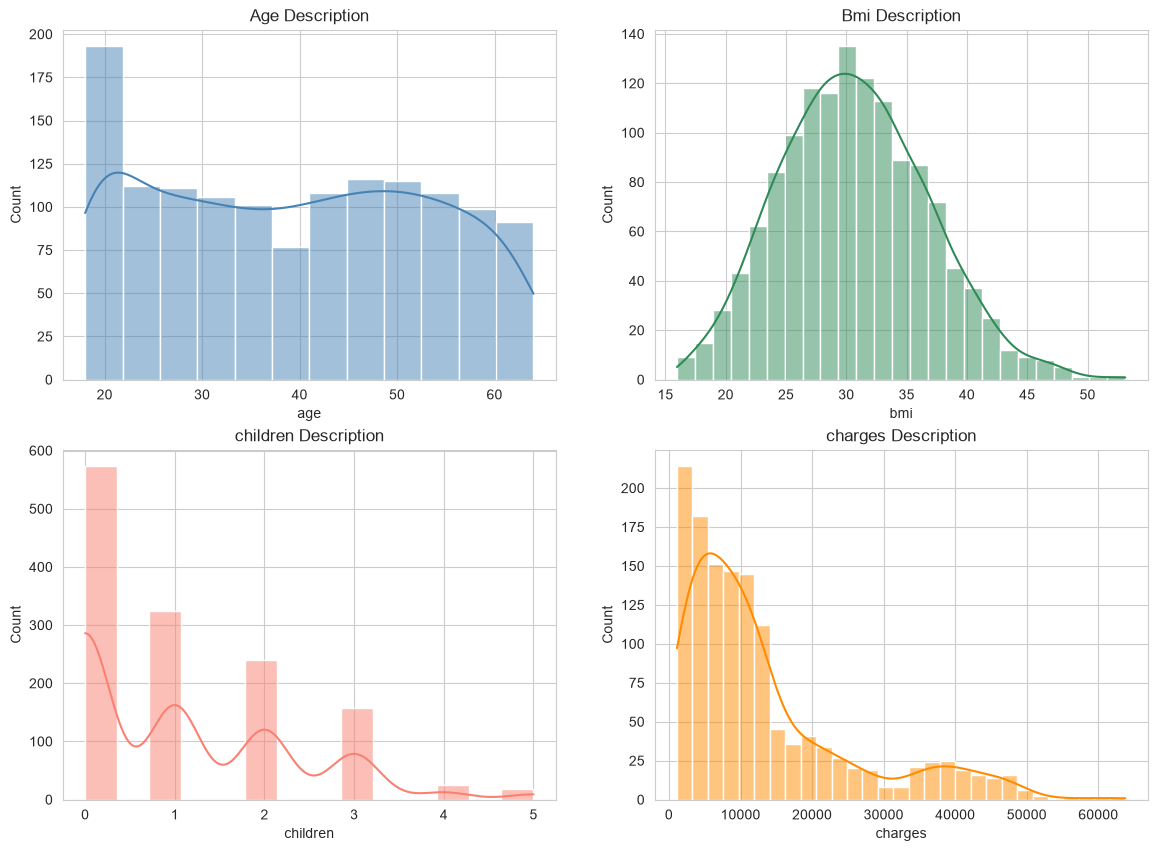

In [36]:
fig, axes = plt.subplots(2,2, figsize=(14,10))
sns.histplot(df["age"], kde=True, ax= axes[0,0], color="steelblue")
axes[0,0].set_title("Age Description")


sns.histplot(df["bmi"], kde=True, ax= axes[0,1], color="seagreen")
axes[0,1].set_title("Bmi Description")

sns.histplot(df["children"], kde=True, ax= axes[1,0], color="salmon")
axes[1,0].set_title("children Description")

sns.histplot(df["charges"], kde=True, ax= axes[1,1], color="darkorange")
axes[1,1].set_title("charges Description")

### 4.4 Outliers (IQR rule)
An **outlier** is an unusually extreme value. The IQR rule works like this:
1. Q1 and Q3 are the values below which 25% and 75% of the data fall. `IQR = Q3 - Q1` is the spread of the middle half.
2. Anything below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` is flagged as an outlier.

**What we see:** only 9 `bmi` outliers (0.7%), but **139 `charges` outliers (10.4%)**, all at the high end.

**Decision:** we keep them. These high charges are real customers (mostly smokers), not mistakes. Removing them would stop the model from learning to predict expensive cases.

In [37]:
for col in ["bmi", "charges"]:

    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    n_out = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: bounds = ({lower:.1f}, {upper:.1f}), outliers = {n_out} ({n_out/len(df) * 100: .1f}%)")

bmi: bounds = (13.7, 47.3), outliers = 9 ( 0.7%)
charges: bounds = (-13120.7, 34524.8), outliers = 139 ( 10.4%)


### 4.5 Smokers vs non-smokers
`groupby("smoker")["charges"].agg([...])` splits the people into smokers and non-smokers and calculates the mean, median, spread and count of `charges` for each group.

**What we see:**

| | Non-smokers | Smokers |
|---|---|---|
| Average charge | **$8,441** | **$32,050** |
| People | 1,063 | 274 |

Smokers pay about **3.8 times more** on average. This is the strongest pattern in the whole dataset. (These two averages are the reference values shown in the web app's comparison chart.)

In [38]:
df.columns
df.groupby("smoker")["charges"].agg(["mean", "median","std", "count"])

,mean,median,std,count
smoker,,,,
no,8440.660307,7345.72660,5992.973800,1063
yes,32050.231832,34456.34845,11541.547176,274


## Step 5: Feature engineering

### 5.1 Create a BMI category
`bmi_category()` turns the BMI number into a standard health group:

| BMI | Category |
|---|---|
| below 18.5 | underweight |
| 18.5 to 24.9 | normal |
| 25 to 29.9 | overweight |
| 30 and above | obese |

`.apply(bmi_category)` runs the function on every row to create the new column `bmi_category`. We add this because the effect of BMI is not a straight line: the cost jumps once a person is in the obese range.

In [39]:
def bmi_category(bmi):
    if bmi<18.5:
        return "underweight"
    elif bmi<25:
        return "normal"
    elif bmi < 30:
        return "overweight"
    else:
        return "obese"
df["bmi_category"] = df["bmi"].apply(bmi_category)
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,overweight
1,18,male,33.770,1,no,southeast,1725.55230,obese
2,28,male,33.000,3,no,southeast,4449.46200,obese
3,33,male,22.705,0,no,northwest,21984.47061,normal
4,32,male,28.880,0,no,northwest,3866.85520,overweight


### 5.2 Do the BMI categories differ in cost?
We calculate the average `charges` per BMI category and sort from lowest to highest.

**What we see:** underweight about $8,852, normal about $10,409, overweight about $10,988, and **obese about $15,572**. Obese people cost clearly more, so the new feature carries useful information.

In [40]:
df.groupby("bmi_category")["charges"].mean().sort_values().round(2)

bmi_category
underweight     8852.20
normal         10409.34
overweight     10987.51
obese          15572.04
Name: charges, dtype: float64

### 5.3 Log-transform the target
`np.log1p(x)` calculates `log(1 + x)`. The "+1" avoids a problem if a value is 0. We store the result in a new column `log_charges`.

**Why?** `charges` is strongly right-skewed. A log transform pulls the long tail in, so the distribution is closer to a bell curve. Models usually learn more stably from that, and large charges no longer dominate the errors. We will convert predictions back to dollars later with `np.expm1` (the exact reverse).

In [41]:
df["log_charges"] = np.log1p(df["charges"])


### Check: skewness before the transform
The skewness of the original `charges` is about **1.52**, clearly right-skewed.

In [42]:
df["charges"].skew()

np.float64(1.5153909108403483)

### Check: skewness after the transform
The skewness of `log_charges` is about **-0.09**, very close to 0. The transform worked: the distribution is now almost symmetric.

In [43]:
df["log_charges"].skew()

np.float64(-0.08955835073325419)

## Step 6: Encoding and preparing the model data

### 6.1 One-hot encoding of the text columns
Models cannot read words, so we convert each text column into 0/1 columns with `pd.get_dummies`. For example `smoker` becomes `smoker_yes` (1 = yes, 0 = no).

`drop_first=True` removes one category of each column to avoid duplicated information (the *dummy variable trap*). The dropped category is implied when all the other columns are 0:

| Column | Category that is dropped (the baseline) |
|---|---|
| `sex` | female |
| `smoker` | no |
| `region` | northeast |
| `bmi_category` | normal |

**Important:** the web app must create exactly the same columns, which is what `build_input_row` does in `app.py`.

In [44]:
df_model = pd.get_dummies(
    df, 
    columns=["sex", "smoker", "region", "bmi_category"],
    drop_first=True
)
print(df_model.columns)

Index(['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_obese', 'bmi_category_overweight',
       'bmi_category_underweight'],
      dtype='str')


### 6.2 Look at the encoded table
The table now has only numeric or True/False columns. `True`/`False` are treated as 1/0 by scikit-learn, so this works as it is.

In [45]:
df_model.head()

,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_obese,bmi_category_overweight,bmi_category_underweight
0,19,27.900,0,16884.92400,9.734236,False,True,False,False,True,False,True,False
1,18,33.770,1,1725.55230,7.453882,True,False,False,True,False,True,False,False
2,28,33.000,3,4449.46200,8.400763,True,False,False,True,False,True,False,False
3,33,22.705,0,21984.47061,9.998137,True,False,True,False,False,False,False,False
4,32,28.880,0,3866.85520,8.260455,True,False,True,False,False,False,True,False


### 6.3 Define the inputs (X) and the answer (y)
- **`feature_cols`**: the list of columns the model learns from, which is every column **except** `charges` and `log_charges`.
- **`x`**: the table of those input columns.
- **`y`**: the answer we want to predict, `log_charges`.

⚠️ We must exclude **both** `charges` and `log_charges` from the inputs. They *are* the answer (one is just a transform of the other), so leaving them in would let the model cheat (*data leakage*) and the scores would look perfect but be meaningless.

In [46]:
feature_cols =  [c for c in df_model.columns if c not in ["charges","log_charges"]]
x  = df_model[feature_cols]
y = df_model["log_charges"]

## Step 7: Train/test split

### 7.1 Hold back data for an honest test
`train_test_split(x, y, test_size=0.2)` randomly puts **80%** of the people in a *training* set (the models learn from it) and **20%** in a *test* set (kept hidden until the end).

**Why?** If we tested on the same people the model learned from, it could simply memorize them and look perfect, but fail on new people. The test set shows how it behaves on people it has never seen.

> 💡 **Tip:** there is no `random_state`, so every run gives a different split and slightly different scores. Add `random_state=42` to get repeatable results.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2)

## Step 8: Train and compare the models

### 8.1 The three models
| Model | Idea in plain words |
|---|---|
| **Linear Regression** | Draws the best straight-line (weighted sum) relationship. Simple and fast, but can only capture straight-line effects. |
| **Random Forest** | 300 decision trees (each a flowchart of yes/no questions) trained on different samples; their answers are averaged. `max_depth=8` limits how deep each tree goes to avoid memorizing. |
| **Gradient Boosting** | Builds 300 small trees *one after another*, each one correcting the mistakes of the previous ones. `learning_rate=0.05` makes each tree correct only a small part, and `max_depth=3` keeps trees small. |

### 8.2 What the loop does
For each model it:
1. **trains** it with `model.fit(X_train, y_train)`,
2. **predicts** the log charges for the test people,
3. converts predictions back to dollars with `np.expm1` (`y_test_real` holds the true dollar amounts),
4. calculates three scores and stores them.

### The three scores
- **R²**: the share of the variation in charges the model explains. 1.0 = perfect, 0 = no better than always guessing the average.
- **MAE** (mean absolute error): the average size of the mistake in dollars. Easy to explain.
- **RMSE** (called `RSME` in the code): like MAE but punishes big mistakes more.

**What we see:**

| Model | R² | MAE | RMSE |
|---|---|---|---|
| Linear Regression | 0.52 | $3,983 | $7,965 |
| Random Forest | 0.86 | $2,079 | $4,372 |
| Gradient Boosting | **0.87** | **$1,982** | **$4,194** |

The two tree-based models are far better than Linear Regression. This tells us the relationship is **not a straight line**, because smoking and BMI interact (a high BMI costs much more for smokers). Trees capture such interactions automatically.

In [48]:
y_test_real = np.expm1(y_test)

candidate_models = {
    "Linear Regression" : LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=8, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, max_depth= 3, learning_rate=0.05)
}

trained_models = {}
metrics_rows = []

for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)

    r2 = r2_score(y_test_real, y_pred)
    mae = mean_absolute_error(y_test_real, y_pred)
    rsme = np.sqrt(mean_squared_error(y_test_real, y_pred))

    trained_models[name] = model
    metrics_rows.append({"Model":name, "R2":r2, "MAE":mae, "RSME":rsme })
    print(f"Model : {name} -> R2:{r2:.4f} - MAE: {mae:.2f} - RSME :{rsme:.2f}")


Model : Linear Regression -> R2:0.5222 - MAE: 3782.55 - RSME :7768.81
Model : Random Forest -> R2:0.8541 - MAE: 1916.92 - RSME :4292.53
Model : Gradient Boosting -> R2:0.8284 - MAE: 2101.44 - RSME :4656.25


### 8.3 The raw scores
The stored results as a list of dictionaries, one per model. This is just the raw material for the next table.

In [49]:
metrics_rows

[{'Model': 'Linear Regression',
  'R2': 0.5221881880318104,
  'MAE': 3782.546098821089,
  'RSME': np.float64(7768.813417773708)},
 {'Model': 'Random Forest',
  'R2': 0.8541275551599076,
  'MAE': 1916.9190673785415,
  'RSME': np.float64(4292.525474961888)},
 {'Model': 'Gradient Boosting',
  'R2': 0.8283596926090615,
  'MAE': 2101.4371521270155,
  'RSME': np.float64(4656.2457335726995)}]

### 8.4 Ranking table
We turn the list into a table, sort by R² from best to worst (`sort_values("R2", ascending=False)`) and renumber the rows. **Gradient Boosting is first**, with Random Forest close behind and Linear Regression far behind.

In [50]:
result = pd.DataFrame(metrics_rows).sort_values("R2", ascending=False).reset_index(drop=True)
result

,Model,R2,MAE,RSME
0,Random Forest,0.854128,1916.919067,4292.525475
1,Gradient Boosting,0.828360,2101.437152,4656.245734
2,Linear Regression,0.522188,3782.546099,7768.813418


### 8.5 Pick the best model
`result.loc[0, "Model"]` takes the name in the first row (the best R²), and `trained_models[...]` fetches that already-trained model object. We call it `best_model`.

In [51]:
best_model_name = result.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal 

## Step 9: Save the model for the web app

A trained model only exists in memory while the notebook runs. `joblib.dump(object, "file.pkl")` writes it to a file so that another program (the Streamlit app) can load it later.

| File | Contents | Why the app needs it |
|---|---|---|
| `medical_insurance_model.pkl` | The trained Gradient Boosting model | To make predictions |
| `model_features.pkl` | The exact list and order of input columns | The app must give the model its inputs in exactly this order |
| `model_name.pkl` | The model's name | Information only |

In [52]:
joblib.dump(best_model, "medical_insurance_model.pkl")
joblib.dump(feature_cols, "model_features.pkl")
joblib.dump(best_model_name, "model_name.pkl")

['model_name.pkl']

---
## Summary

### What we found
- **Smoking is the biggest cost driver.** Smokers pay on average about $32,050 a year versus about $8,441 for non-smokers (about 3.8 times more).
- **A higher BMI means higher cost**, especially in the obese range (average about $15,572).
- **Charges are right-skewed**, so predicting the log of the charges works better.
- **Tree-based models beat Linear Regression by a wide margin** (R² about 0.86 to 0.87 against 0.52), because the effects interact and are not straight lines.

### Final model
**Gradient Boosting** with an R² of about **0.87**, an average error (MAE) of about **$2,000**, and an RMSE of about **$4,200** on people the model has never seen.

### Limitations (good to know)
- The dataset is small (1,337 unique people), so scores can change a little with a different random split.
- The comparison used a single train/test split. **Cross-validation** would give a more reliable estimate.
- The model only knows these 6 inputs. Real insurance prices depend on many more factors, so this is a learning project and not a pricing tool.

### Ideas to improve
1. Set `random_state` everywhere for repeatable results.
2. Tune the settings of Gradient Boosting (`n_estimators`, `learning_rate`, `max_depth`) with cross-validation.
3. Add an interaction feature such as `smoker × bmi`.
4. Try other models, such as XGBoost.

### The web app
`Medical_Insurance_Cost_Prediction_app.py` loads the saved model and shows a form (age, sex, BMI, children, smoker, region). When the user clicks *Estimate charges*, it builds one row in the same format as the training data, predicts the log charges, converts them to dollars with `np.expm1`, and compares the result with the average non-smoker and smoker charges. Run it with `streamlit run Medical_Insurance_Cost_Prediction_app.py`.